In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/crackathon-data/randomized_dataset/val/labels/023038.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/029467.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/020738.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/030882.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/034602.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/020936.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/037752.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/034138.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/006439.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/002979.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/000870.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/004343.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/013256.txt
/kaggle/input/crackathon-data/randomized_dataset/val/labels/004396.txt
/kaggl

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anulayakhare/crackathon-data")

print("Path to dataset files:", path)

🚀 Scanning for label files in: /kaggle/input/crackathon-data/randomized_dataset
✅ Found 32385 label files. Reading data...


100%|██████████| 32385/32385 [00:17<00:00, 1818.52it/s]
/tmp/ipykernel_55/1636690905.py:95: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df, x='class_name', order=df['class_name'].value_counts().index, palette='viridis')



📊 DATASET INTELLIGENCE REPORT
Total Labels Scanned: 32385
Total Damage Objects: 55338
Empty Images (Background): 9865
----------------------------------------


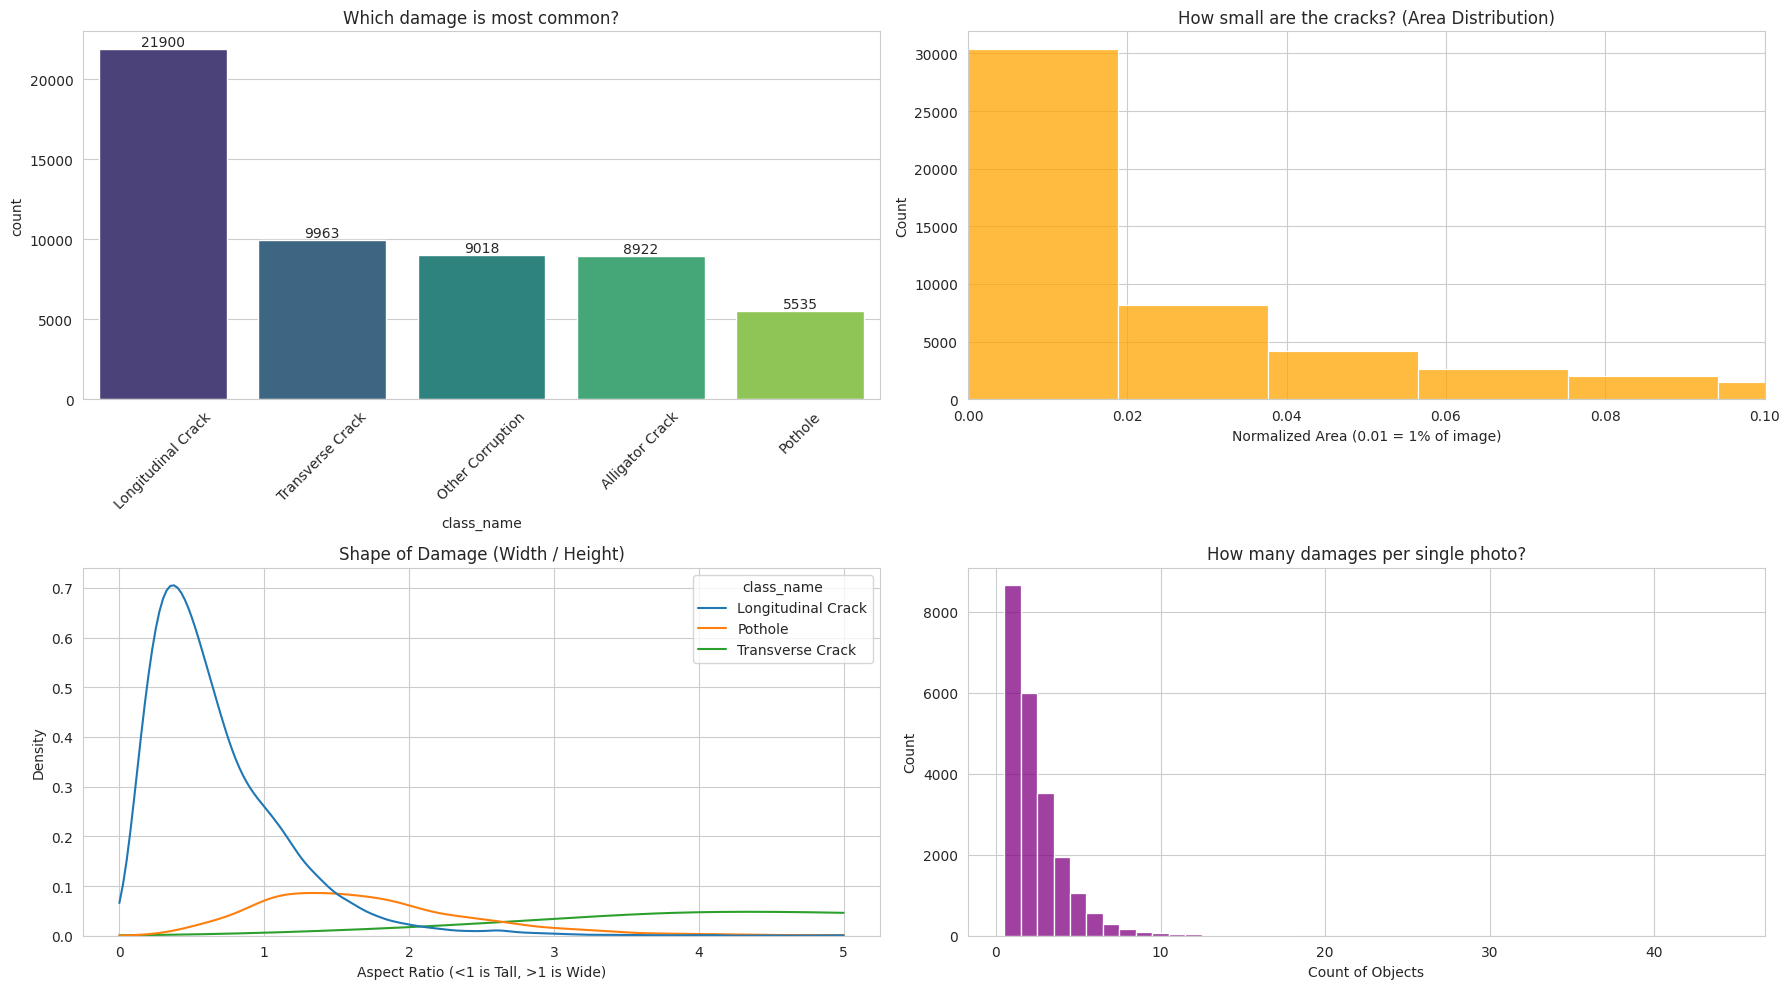


💡 INSTANT RECOMMENDATIONS:
1. Potholes are 10.00% of the data.
2. Average Object Size: 0.0463


In [5]:
import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np

# ==========================================
# 1. SETUP (Fixed for your Kaggle path)
# ==========================================
# Based on your file tree screenshot
DATASET_ROOT = "/kaggle/input/crackathon-data/randomized_dataset"
SEARCH_PATTERN = "**/labels/*.txt"

CLASS_MAP = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Other Corruption",
    4: "Pothole"
}

# ==========================================
# 2. DATA PARSING
# ==========================================
print(f"🚀 Scanning for label files in: {DATASET_ROOT}")
# recursive=True ensures we look inside train/labels AND val/labels
txt_files = glob.glob(os.path.join(DATASET_ROOT, SEARCH_PATTERN), recursive=True)

print(f"✅ Found {len(txt_files)} label files. Reading data...")

data_records = []
empty_count = 0

for file_path in tqdm(txt_files):
    filename = os.path.basename(file_path)
    
    # Check if file is empty (No damage in image)
    if os.path.getsize(file_path) == 0:
        empty_count += 1
        continue

    with open(file_path, 'r') as f:
        lines = f.readlines()
        
        # Double check for empty lines
        if not lines:
            empty_count += 1
            continue
            
        for line in lines:
            parts = line.strip().split()
            # Safety check: Ensure line has 5 numbers
            if len(parts) >= 5:
                try:
                    cls_id = int(parts[0])
                    x, y, w, h = map(float, parts[1:5])
                    
                    data_records.append({
                        'filename': filename,
                        'class_id': cls_id,
                        'class_name': CLASS_MAP.get(cls_id, "Unknown"),
                        'width': w,
                        'height': h,
                        'area': w * h,
                        'aspect_ratio': w / h if h > 0 else 0
                    })
                except ValueError:
                    continue # Skip malformed lines

# Create the Table
df = pd.DataFrame(data_records)

# ==========================================
# 3. THE ANALYSIS (The "Boring" Truth)
# ==========================================
if len(df) == 0:
    print("\n❌ CRITICAL ERROR: No valid labels found. Check the path again.")
else:
    print("\n" + "="*40)
    print("📊 DATASET INTELLIGENCE REPORT")
    print("="*40)
    print(f"Total Labels Scanned: {len(txt_files)}")
    print(f"Total Damage Objects: {len(df)}")
    print(f"Empty Images (Background): {empty_count}")
    print("-" * 40)

    # VISUALIZATION
    sns.set_style("whitegrid")
    fig = plt.figure(figsize=(18, 10))

    # 1. Class Imbalance (The most important chart)
    plt.subplot(2, 2, 1)
    ax = sns.countplot(data=df, x='class_name', order=df['class_name'].value_counts().index, palette='viridis')
    plt.xticks(rotation=45)
    plt.title("Which damage is most common?")
    for container in ax.containers:
        ax.bar_label(container)

    # 2. Object Size (Do we need high-res?)
    plt.subplot(2, 2, 2)
    sns.histplot(data=df, x='area', bins=50, color='orange')
    plt.title("How small are the cracks? (Area Distribution)")
    plt.xlabel("Normalized Area (0.01 = 1% of image)")
    plt.xlim(0, 0.1) # Zoom in on small objects

    # 3. Shape Analysis (Aspect Ratio)
    plt.subplot(2, 2, 3)
    # Filter for the 3 main types to keep chart clean
    target_classes = ["Longitudinal Crack", "Transverse Crack", "Pothole"]
    sns.kdeplot(data=df[df['class_name'].isin(target_classes)], x='aspect_ratio', hue='class_name', clip=(0, 5))
    plt.title("Shape of Damage (Width / Height)")
    plt.xlabel("Aspect Ratio (<1 is Tall, >1 is Wide)")

    # 4. Damage per Image
    plt.subplot(2, 2, 4)
    counts = df['filename'].value_counts()
    sns.histplot(counts, bins=range(1, 10), discrete=True, color='purple')
    plt.title("How many damages per single photo?")
    plt.xlabel("Count of Objects")

    plt.tight_layout()
    plt.show()

    # ==========================================
    # 4. ACTIONABLE INSIGHTS
    # ==========================================
    print("\n💡 INSTANT RECOMMENDATIONS:")
    
    # Check for Pothole rarity
    pothole_count = len(df[df['class_name'] == 'Pothole'])
    total_count = len(df)
    pothole_pct = (pothole_count / total_count) * 100
    print(f"1. Potholes are {pothole_pct:.2f}% of the data.")
    if pothole_pct < 10:
        print("   -> ALERT: Potholes are rare. You MUST use oversampling or the model will ignore them.")
    
    # Check for Tiny Objects
    avg_area = df['area'].mean()
    print(f"2. Average Object Size: {avg_area:.4f}")
    if avg_area < 0.02:
        print("   -> ALERT: Objects are TINY. Standard YOLOv8n will fail. Use YOLOv8-P6 (1280px) models.")

🚀 Scanning for label files in: /kaggle/input/crackathon-data/randomized_dataset
✅ Found 32385 label files. Reading data...


100%|██████████| 32385/32385 [00:19<00:00, 1692.33it/s]
/tmp/ipykernel_55/999259120.py:100: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(



📊 DATASET INTELLIGENCE REPORT
Total Label Files      : 32385
Total Damage Objects   : 55338
Empty Images (No objs) : 9865
Avg Objects / Image    : 2.46
---------------------------------------------


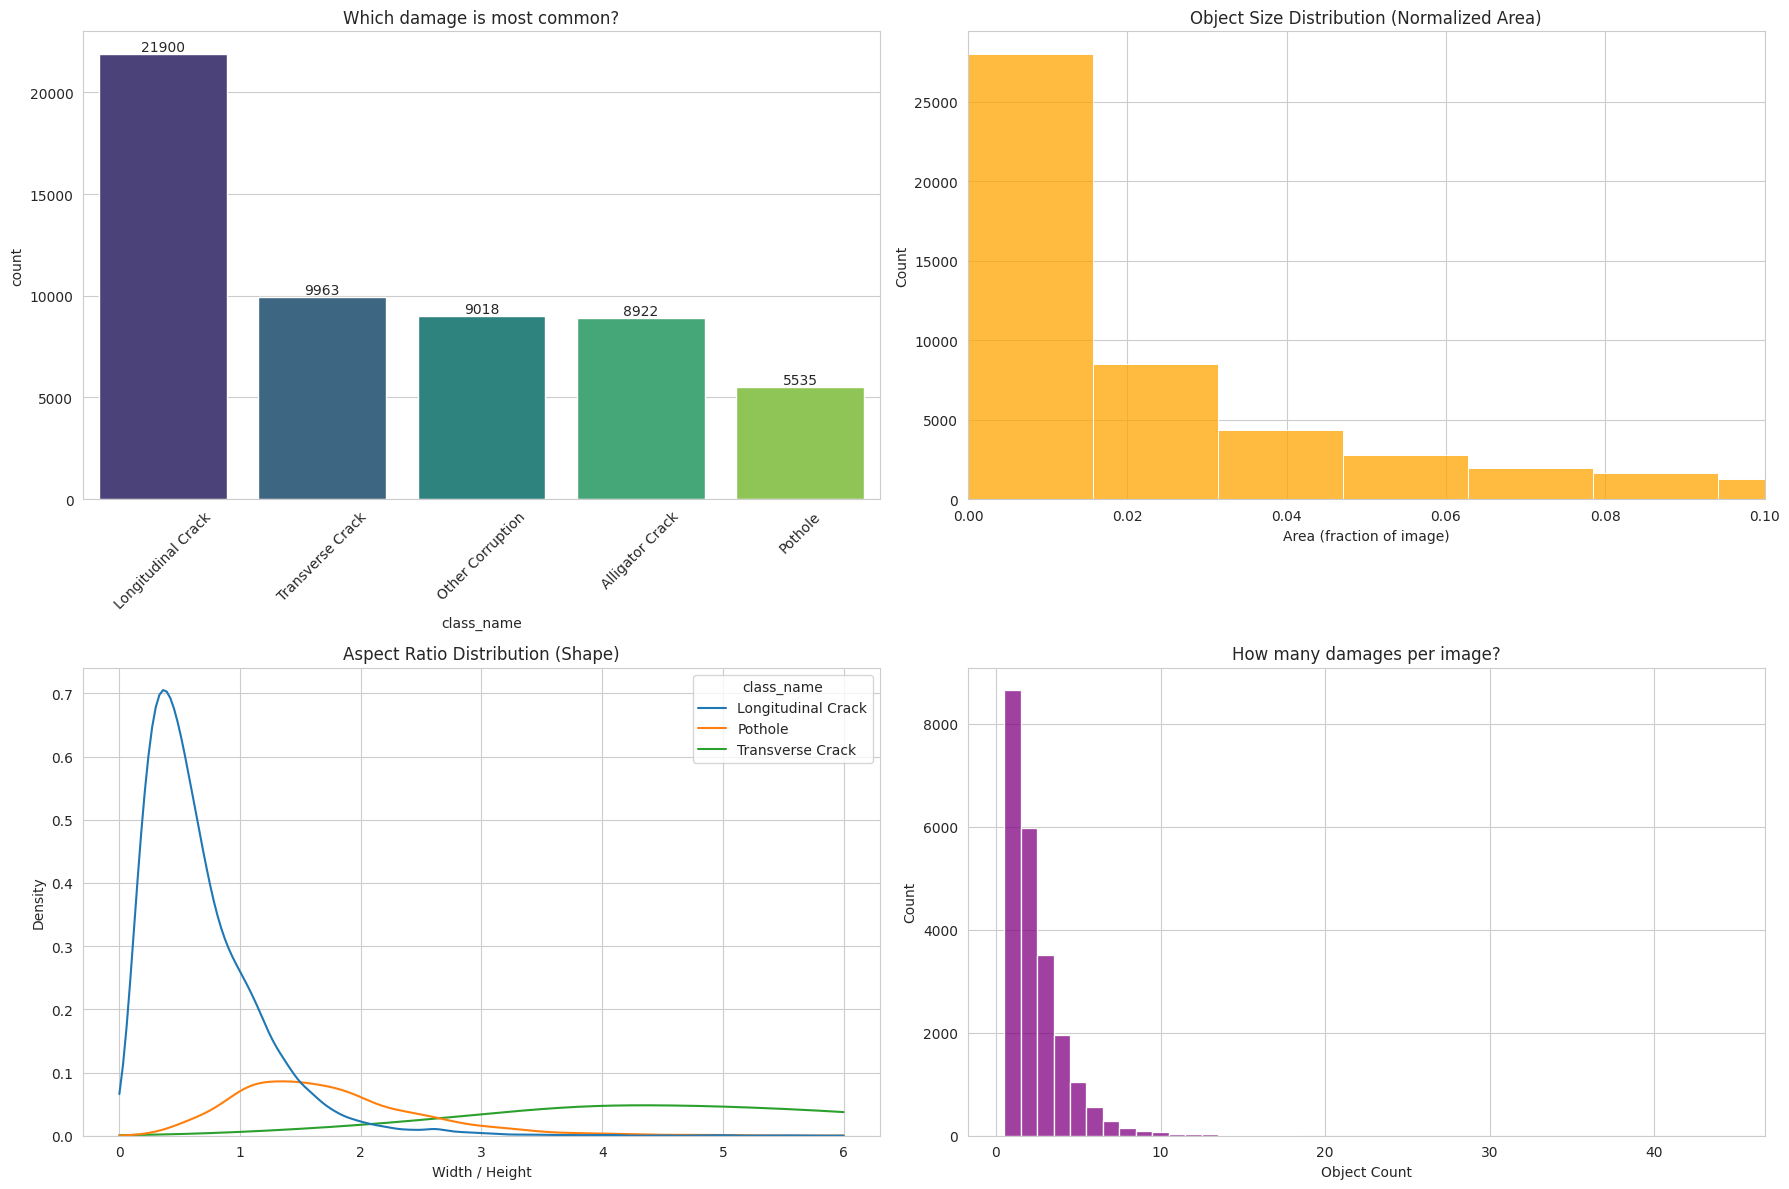

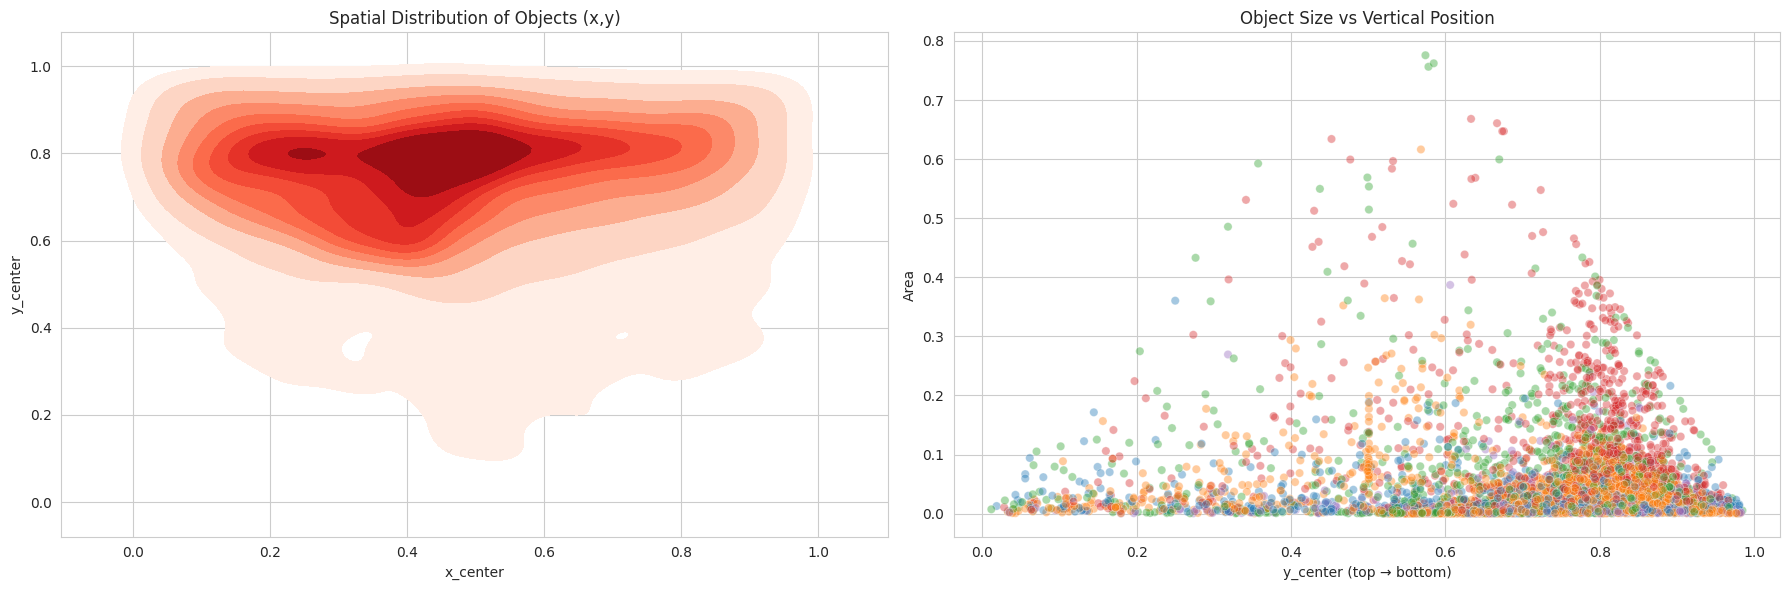


📐 PER-CLASS GEOMETRY SUMMARY
---------------------------------------------
                      area                 aspect_ratio                 
                      0.05    0.50    0.95         0.05    0.50     0.95
class_name                                                              
Alligator Crack     0.0083  0.0827  0.3583       0.5643  1.3610   3.5382
Longitudinal Crack  0.0004  0.0117  0.0992       0.1553  0.5534   1.5941
Other Corruption    0.0011  0.0260  0.2438       0.5193  1.5583   5.2856
Pothole             0.0006  0.0053  0.0635       0.6857  1.6000   3.1917
Transverse Crack    0.0014  0.0108  0.0824       2.0330  5.0715  11.5289

🔗 CLASS CO-OCCURRENCE MATRIX
---------------------------------------------


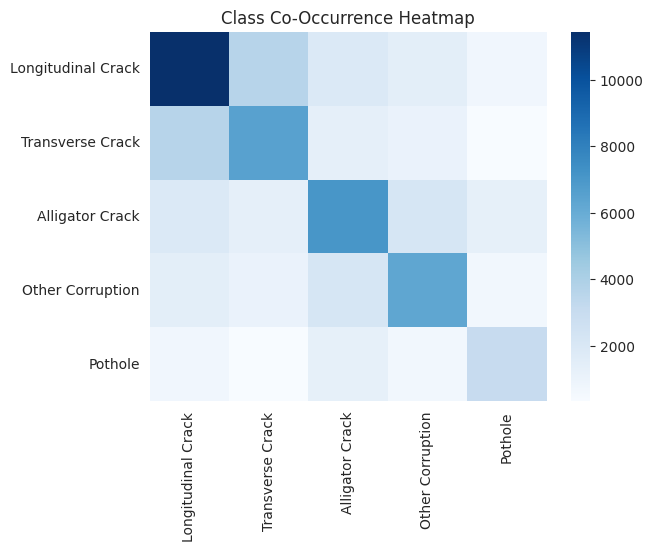


🔍 TINY OBJECT ANALYSIS
---------------------------------------------
Objects < 0.5% area : 25.55%

💡 FINAL MODELING RECOMMENDATIONS
• Potholes share        : 10.00%
• Average object area   : 0.0463
• Tiny objects (<0.5%)  : 25.55%
• Empty images          : 9865 (30.5%)


In [9]:
# ==========================================================
# FULL DATA-SCIENTIST EDA FOR OBJECT DETECTION
# ==========================================================

import os
import glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np

# ==========================================================
# 1. SETUP
# ==========================================================

DATASET_ROOT = "/kaggle/input/crackathon-data/randomized_dataset"
SEARCH_PATTERN = "**/labels/*.txt"

CLASS_MAP = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Other Corruption",
    4: "Pothole"
}

sns.set_style("whitegrid")

# ==========================================================
# 2. DATA PARSING
# ==========================================================

print(f"🚀 Scanning for label files in: {DATASET_ROOT}")
txt_files = glob.glob(os.path.join(DATASET_ROOT, SEARCH_PATTERN), recursive=True)

print(f"✅ Found {len(txt_files)} label files. Reading data...")

data_records = []
empty_count = 0

for file_path in tqdm(txt_files):
    filename = os.path.basename(file_path)

    if os.path.getsize(file_path) == 0:
        empty_count += 1
        continue

    with open(file_path, "r") as f:
        lines = f.readlines()
        if not lines:
            empty_count += 1
            continue

        for line in lines:
            parts = line.strip().split()
            if len(parts) >= 5:
                try:
                    cls_id = int(parts[0])
                    x, y, w, h = map(float, parts[1:5])

                    data_records.append({
                        "filename": filename,
                        "class_id": cls_id,
                        "class_name": CLASS_MAP.get(cls_id, "Unknown"),
                        "x_center": x,
                        "y_center": y,
                        "width": w,
                        "height": h,
                        "area": w * h,
                        "aspect_ratio": w / h if h > 0 else np.nan
                    })
                except:
                    continue

df = pd.DataFrame(data_records)

# ==========================================================
# 3. BASIC DATASET SUMMARY
# ==========================================================

print("\n" + "="*45)
print("📊 DATASET INTELLIGENCE REPORT")
print("="*45)

print(f"Total Label Files      : {len(txt_files)}")
print(f"Total Damage Objects   : {len(df)}")
print(f"Empty Images (No objs) : {empty_count}")
print(f"Avg Objects / Image    : {len(df) / (len(txt_files)-empty_count):.2f}")
print("-"*45)

# ==========================================================
# 4. CORE VISUAL EDA (YOUR ORIGINAL + CLEANED)
# ==========================================================

fig = plt.figure(figsize=(18, 12))

# ---- Class Imbalance ----
plt.subplot(2, 2, 1)
ax = sns.countplot(
    data=df,
    x="class_name",
    order=df["class_name"].value_counts().index,
    palette="viridis"
)
plt.xticks(rotation=45)
plt.title("Which damage is most common?")
for c in ax.containers:
    ax.bar_label(c)

# ---- Object Area ----
plt.subplot(2, 2, 2)
sns.histplot(df["area"], bins=60, color="orange")
plt.title("Object Size Distribution (Normalized Area)")
plt.xlabel("Area (fraction of image)")
plt.xlim(0, 0.1)

# ---- Aspect Ratio ----
plt.subplot(2, 2, 3)
focus_classes = ["Longitudinal Crack", "Transverse Crack", "Pothole"]
sns.kdeplot(
    data=df[df["class_name"].isin(focus_classes)],
    x="aspect_ratio",
    hue="class_name",
    clip=(0, 6)
)
plt.title("Aspect Ratio Distribution (Shape)")
plt.xlabel("Width / Height")

# ---- Objects per Image ----
plt.subplot(2, 2, 4)
obj_per_img = df["filename"].value_counts()
sns.histplot(obj_per_img, bins=range(1, 15), color="purple", discrete=True)
plt.title("How many damages per image?")
plt.xlabel("Object Count")

plt.tight_layout()
plt.show()

# ==========================================================
# 5. ADVANCED SPATIAL EDA (VERY IMPORTANT)
# ==========================================================

fig = plt.figure(figsize=(18, 6))

# ---- Object Center Heatmap ----
plt.subplot(1, 2, 1)
sns.kdeplot(x=df["x_center"], y=df["y_center"], cmap="Reds", fill=True)
plt.title("Spatial Distribution of Objects (x,y)")
plt.xlabel("x_center")
plt.ylabel("y_center")

# ---- Area vs Vertical Position ----
plt.subplot(1, 2, 2)
sns.scatterplot(
    data=df.sample(min(6000, len(df))),
    x="y_center",
    y="area",
    hue="class_name",
    alpha=0.4,
    legend=False
)
plt.title("Object Size vs Vertical Position")
plt.xlabel("y_center (top → bottom)")
plt.ylabel("Area")

plt.tight_layout()
plt.show()

# ==========================================================
# 6. PER-CLASS GEOMETRY STATS (NUMERIC)
# ==========================================================

print("\n📐 PER-CLASS GEOMETRY SUMMARY")
print("-"*45)

geom_stats = (
    df.groupby("class_name")[["area", "aspect_ratio"]]
      .quantile([0.05, 0.5, 0.95])
      .unstack()
      .round(4)
)

print(geom_stats)

# ==========================================================
# 7. CO-OCCURRENCE ANALYSIS
# ==========================================================

print("\n🔗 CLASS CO-OCCURRENCE MATRIX")
print("-"*45)

img_class_map = df.groupby("filename")["class_name"].apply(set)

classes = list(CLASS_MAP.values())
co_matrix = pd.DataFrame(0, index=classes, columns=classes)

for cls_set in img_class_map:
    for c1 in cls_set:
        for c2 in cls_set:
            co_matrix.loc[c1, c2] += 1

sns.heatmap(co_matrix, annot=False, cmap="Blues")
plt.title("Class Co-Occurrence Heatmap")
plt.show()

# ==========================================================
# 8. TINY OBJECT RISK ANALYSIS
# ==========================================================

tiny_threshold = 0.005  # 0.5% of image
tiny_ratio = (df["area"] < tiny_threshold).mean() * 100

print("\n🔍 TINY OBJECT ANALYSIS")
print("-"*45)
print(f"Objects < 0.5% area : {tiny_ratio:.2f}%")

# ==========================================================
# 9. FINAL ACTIONABLE RECOMMENDATIONS
# ==========================================================

print("\n💡 FINAL MODELING RECOMMENDATIONS")
print("="*45)

pothole_pct = (df["class_name"] == "Pothole").mean() * 100
avg_area = df["area"].mean()

print(f"• Potholes share        : {pothole_pct:.2f}%")
print(f"• Average object area   : {avg_area:.4f}")
print(f"• Tiny objects (<0.5%)  : {tiny_ratio:.2f}%")
print(f"• Empty images          : {empty_count} ({empty_count/len(txt_files)*100:.1f}%)")



In [1]:
!ls /kaggle/input


crackathon-data


In [2]:
!ls /kaggle/input/crackathon-data

randomized_dataset


In [4]:
!ls /kaggle/input/crackathon-data/randomized_dataset


test  train  val


In [5]:
data_yaml = """
path: /kaggle/input/<DATASET>/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""

with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml created ✅")


data.yaml created ✅


In [6]:
!cat data.yaml



path: /kaggle/input/<DATASET>/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole


In [7]:
!pip install -q ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 35.0 MB/s eta 0:00:00


In [8]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=6,
    project="runs",
    name="rdd_final"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k

RuntimeError: Dataset 'data.yaml' error ❌ Dataset 'data.yaml' images not found, missing path '/kaggle/input/<DATASET>/randomized_dataset/val/images'
Note dataset download directory is '/kaggle/working/datasets'. You can update this in '/root/.config/Ultralytics/settings.json'

In [9]:
!ls /kaggle/input


crackathon-data


In [10]:
!ls /kaggle/input/crackathon-data


randomized_dataset


In [11]:
!ls /kaggle/input/crackathon-data/randomized_dataset


test  train  val


In [12]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml FIXED ✅")


data.yaml FIXED ✅


In [13]:
!cat data.yaml



path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole


In [14]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=20,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=6,
    project="runs",
    name="rdd_final"
)


Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=rdd_final2, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=6, perspective=0.0, plots=True, pose=12.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x78813447fd10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [13]:
!ls -lah /kaggle/working


total 12K
drwxr-xr-x 3 root root 4.0K Jan  8 04:35 .
drwxr-xr-x 5 root root 4.0K Jan  8 04:35 ..
drwxr-xr-x 2 root root 4.0K Jan  8 04:35 .virtual_documents


In [14]:
model = YOLO("runs/detect/rdd_recovery/weights/best.pt")

model.predict(
    source="/kaggle/input/crackathon-data/randomized_dataset/test/images",
    save_txt=True,
    save_conf=True,
    project="predictions",
    name="test"
)


NameError: name 'YOLO' is not defined

In [15]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

!cat data.yaml



path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images
test: test/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole


In [16]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=12,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=4,
    project="runs",
    name="rdd_recovery"
)


ModuleNotFoundError: No module named 'ultralytics'

In [17]:
!pip install -q ultralytics


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 32.9 MB/s eta 0:00:0000:01


In [18]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=12,
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=4,
    project="runs",
    name="rdd_recovery"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=12, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7fe3c4b03770>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [19]:
from ultralytics import YOLO

model = YOLO("runs/detect/rdd_recovery/weights/best.pt")
print("Best model loaded ✅")


FileNotFoundError: [Errno 2] No such file or directory: 'runs/detect/rdd_recovery/weights/best.pt'

In [20]:

!find /kaggle/working -type d -name "weights"


/kaggle/working/runs/rdd_recovery/weights


In [21]:
from ultralytics import YOLO

model = YOLO("/kaggle/working/runs/rdd_recovery/weights/best.pt")
print("Best model loaded ✅")


Best model loaded ✅


In [ ]:
model.predict(
    source="/kaggle/input/crackathon-data/randomized_dataset/test/images",
    save_txt=True,
    save_conf=True,
    project="predictions",
    name="test"
)



WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

image 1/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000004.jpg: 352x640 (no detections), 50.7ms
image 2/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000019.jpg: 640x640 (no detections), 16.9ms
image 3/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000030.jpg: 640x640 5 longitudinal_cracks, 2 transverse_cracks, 16.2ms
image 4/6000 /kaggle/input/crackathon-data/randomized_dataset/test/images/000

In [2]:
!cd /kaggle/working/predictions/test && ls


labels


In [5]:
!find /kaggle/working -type d -name labels


/kaggle/working/predictions/test/labels


In [7]:
!cd /kaggle/working/predictions/test && ls



labels


In [8]:
!zip -r submission.zip labels


  adding: labels/ (stored 0%)
  adding: labels/015113.txt (deflated 48%)
  adding: labels/015565.txt (deflated 33%)
  adding: labels/016357.txt (deflated 11%)
  adding: labels/018813.txt (deflated 11%)
  adding: labels/013604.txt (deflated 46%)
  adding: labels/016236.txt (deflated 46%)
  adding: labels/021553.txt (deflated 10%)
  adding: labels/013777.txt (deflated 13%)
  adding: labels/001243.txt (deflated 34%)
  adding: labels/020953.txt (deflated 11%)
  adding: labels/024128.txt (deflated 13%)
  adding: labels/003301.txt (deflated 41%)
  adding: labels/017323.txt (deflated 47%)
  adding: labels/007342.txt (deflated 11%)
  adding: labels/021366.txt (deflated 11%)
  adding: labels/013025.txt (deflated 33%)
  adding: labels/008500.txt (deflated 33%)
  adding: labels/003469.txt (deflated 32%)
  adding: labels/013171.txt (deflated 45%)
  adding: labels/013168.txt (deflated 42%)
  adding: labels/013491.txt (deflated 11%)
  adding: labels/008180.txt (deflated 43%)
  adding: labels/020313.

In [6]:
!ls /kaggle/working


In [7]:
!find /kaggle/working -maxdepth 4 -type d


/kaggle/working
/kaggle/working/.virtual_documents


In [1]:
!ls /kaggle/input

crackathon-data


In [2]:
!ls /kaggle/input/crackathon-data/randomized_dataset



test  train  val


In [3]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset
train: train/images
val: val/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("data.yaml ready")


data.yaml ready


In [6]:
!pip install -q ultralytics


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=8,          # VERY SHORT
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=3,
    project="runs",
    name="rdd_model_only"
)


Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=rdd_model_only2, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=3, perspective=0.0, plots=True, pose

In [7]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset

train: train/images
val: val/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("✅ data.yaml fixed")


✅ data.yaml fixed


In [9]:
!pip install -q ultralytics

In [10]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=8,          # VERY SHORT
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=3,
    project="runs",
    name="rdd_model_only"
)


Ultralytics 8.3.249 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=8, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=rdd_model_only4, nbs=64, nms=False, opset=None, optimize=False, optimizer=AdamW, overlap_mask=True, patience=3, perspective=0.0, plots=True, pose

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7da37b1efcb0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
        

In [11]:
!ls runs/detect/rdd_model_only/weights


ls: cannot access 'runs/detect/rdd_model_only/weights': No such file or directory


In [1]:
data_yaml = """
path: /kaggle/input/crackathon-data/randomized_dataset

train: train/images
val: val/images

nc: 5
names:
  - longitudinal_crack
  - transverse_crack
  - alligator_crack
  - other_corruption
  - pothole
"""
with open("data.yaml", "w") as f:
    f.write(data_yaml)

print("✅ data.yaml fixed")


✅ data.yaml fixed


In [2]:
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 47.2 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO("yolov8m.pt")

model.train(
    data="data.yaml",
    epochs=30,         
    imgsz=640,
    batch=16,
    optimizer="AdamW",
    lr0=0.001,
    patience=3,
    project="runs",
    name="rdd_model_only"
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.3.250 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, k

In [1]:
import kagglehub
import os

path = kagglehub.dataset_download("anulayakhare/crackathon-data")

print("Dataset downloaded to:", path)
print("Files in dataset folder:", os.listdir(path))

100%|█████████████████████████████████████| 9.90G/9.90G [12:28<00:00, 14.2MB/s]

Extracting files...


Dataset downloaded to: /Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1
Files in dataset folder: ['randomized_dataset']


In [2]:
import os

DATASET_ROOT = os.path.join(path, "randomized_dataset")

print("Dataset root:", DATASET_ROOT)
print("\nFolder structure:")

for root, dirs, files in os.walk(DATASET_ROOT):
    level = root.replace(DATASET_ROOT, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

Dataset root: /Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset

Folder structure:
randomized_dataset/
  test/
    images/
  train/
    images/
    labels/
  val/
    images/
    labels/


In [3]:
import glob

label_files = glob.glob(
    os.path.join(DATASET_ROOT, "**", "labels", "*.txt"),
    recursive=True
)

print("Total label files found:", len(label_files))
print("Sample label files:")

for f in label_files[:5]:
    print(f)

Total label files found: 32385
Sample label files:
/Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/labels/019065.txt
/Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/labels/016356.txt
/Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/labels/026295.txt
/Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/labels/006145.txt
/Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/labels/010727.txt


In [4]:
import os
from pathlib import Path

DATASET_ROOT = Path(path) / "randomized_dataset"

splits = ["train", "val", "test"]

print("=" * 55)
print("ROAD DAMAGE DATASET SUMMARY")
print("=" * 55)

for split in splits:
    image_dir = DATASET_ROOT / split / "images"
    label_dir = DATASET_ROOT / split / "labels"

    images = []
    if image_dir.exists():
        images = [
            f for f in image_dir.iterdir()
            if f.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

    labels = list(label_dir.glob("*.txt")) if label_dir.exists() else []

    print(f"\n{split.upper()} SET")
    print("-" * 30)
    print("Images:", len(images))
    print("Label files:", len(labels))

    if labels:
        empty_labels = sum(f.stat().st_size == 0 for f in labels)
        print("Empty label files:", empty_labels)

    image_stems = {f.stem for f in images}
    label_stems = {f.stem for f in labels}

    print("Images without matching labels:",
          len(image_stems - label_stems))
    print("Labels without matching images:",
          len(label_stems - image_stems))

ROAD DAMAGE DATASET SUMMARY

TRAIN SET
------------------------------
Images: 26385
Label files: 26385
Empty label files: 8073
Images without matching labels: 0
Labels without matching images: 0

VAL SET
------------------------------
Images: 6000
Label files: 6000
Empty label files: 1792
Images without matching labels: 0
Labels without matching images: 0

TEST SET
------------------------------
Images: 6000
Label files: 0
Images without matching labels: 6000
Labels without matching images: 0


In [5]:

import os
import pandas as pd
import numpy as np
from pathlib import Path
from tqdm import tqdm

DATASET_ROOT = Path(path) / "randomized_dataset"

CLASS_MAP = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Other Corruption",
    4: "Pothole"
}

records = []
invalid_lines = 0
unknown_classes = 0

for split in ["train", "val"]:
    label_dir = DATASET_ROOT / split / "labels"

    for file in tqdm(list(label_dir.glob("*.txt")), desc=split):
        with open(file, "r") as f:
            for line in f:
                parts = line.strip().split()

                if not parts:
                    continue

                if len(parts) != 5:
                    invalid_lines += 1
                    continue

                try:
                    cls_id = int(parts[0])
                    x, y, w, h = map(float, parts[1:])

                    if cls_id not in CLASS_MAP:
                        unknown_classes += 1
                        continue

                    if not all(np.isfinite(v) for v in [x, y, w, h]):
                        invalid_lines += 1
                        continue

                    if not (0 <= x <= 1 and 0 <= y <= 1
                            and 0 < w <= 1 and 0 < h <= 1):
                        invalid_lines += 1
                        continue

                    records.append({
                        "split": split,
                        "image": f"{split}/{file.stem}",
                        "class_id": cls_id,
                        "class_name": CLASS_MAP[cls_id],
                        "x_center": x,
                        "y_center": y,
                        "width": w,
                        "height": h,
                        "area": w * h,
                        "aspect_ratio": w / h
                    })

                except ValueError:
                    invalid_lines += 1

df = pd.DataFrame(records)

print("\nANNOTATION ANALYSIS")
print("=" * 45)
print("Total annotated damage objects:", len(df))
print("Invalid annotation lines:", invalid_lines)
print("Unknown class IDs:", unknown_classes)

print("\nCLASS DISTRIBUTION")
print(df["class_name"].value_counts())

print("\nSPLIT-WISE OBJECT COUNTS")
print(pd.crosstab(df["split"], df["class_name"]))

print("\nFIRST FIVE ANNOTATIONS")
print(df.head())


val: 100%|███████████████████████████████| 6000/6000 [00:00<00:00, 9300.91it/s]


ANNOTATION ANALYSIS
Total annotated damage objects: 55337
Invalid annotation lines: 1
Unknown class IDs: 0

CLASS DISTRIBUTION
class_name
Longitudinal Crack    21900
Transverse Crack       9963
Other Corruption       9018
Alligator Crack        8921
Pothole                5535
Name: count, dtype: int64

SPLIT-WISE OBJECT COUNTS
class_name  Alligator Crack  Longitudinal Crack  Other Corruption  Pothole  \
split                                                                        
train                  7223               17807              7281     4450   
val                    1698                4093              1737     1085   

class_name  Transverse Crack  
split                         
train                   8133  
val                     1830  

FIRST FIVE ANNOTATIONS
   split         image  class_id          class_name  x_center  y_center  \
0  train  train/019065         2     Alligator Crack  0.821834  0.854998   
1  train  train/016356         2     Alligator Crack  0.

Matplotlib is building the font cache; this may take a moment.


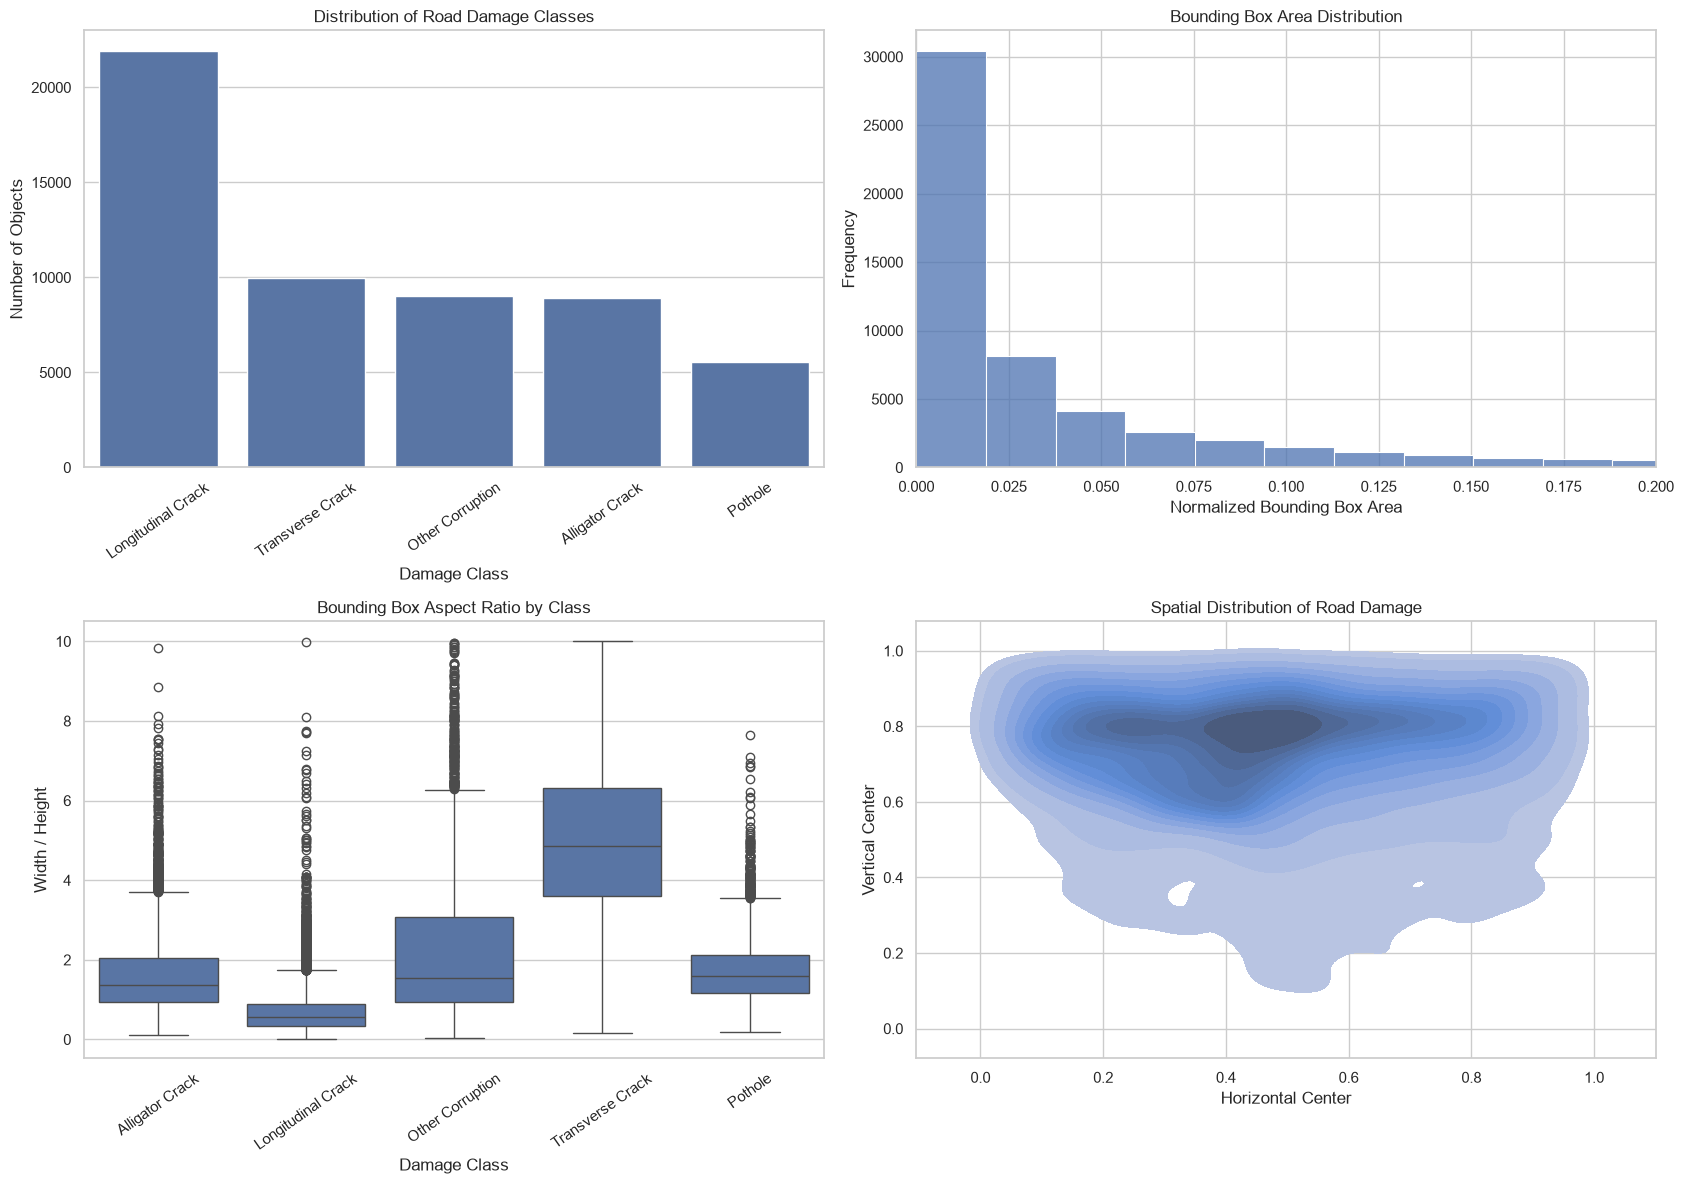

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

sns.set_theme(style="whitegrid")

# Create a 2 x 2 visualization
fig, axes = plt.subplots(2, 2, figsize=(17, 12))

# 1. Class distribution
class_order = df["class_name"].value_counts().index

sns.countplot(
    data=df,
    x="class_name",
    order=class_order,
    ax=axes[0, 0]
)

axes[0, 0].set_title("Distribution of Road Damage Classes")
axes[0, 0].set_xlabel("Damage Class")
axes[0, 0].set_ylabel("Number of Objects")
axes[0, 0].tick_params(axis="x", rotation=35)

# 2. Object area distribution
sns.histplot(
    data=df,
    x="area",
    bins=50,
    ax=axes[0, 1]
)

axes[0, 1].set_title("Bounding Box Area Distribution")
axes[0, 1].set_xlabel("Normalized Bounding Box Area")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].set_xlim(0, 0.2)

# 3. Aspect ratio by class
focus = df[df["aspect_ratio"] <= 10]

sns.boxplot(
    data=focus,
    x="class_name",
    y="aspect_ratio",
    ax=axes[1, 0]
)

axes[1, 0].set_title("Bounding Box Aspect Ratio by Class")
axes[1, 0].set_xlabel("Damage Class")
axes[1, 0].set_ylabel("Width / Height")
axes[1, 0].tick_params(axis="x", rotation=35)

# 4. Object center distribution
sns.kdeplot(
    x=df["x_center"],
    y=df["y_center"],
    fill=True,
    levels=15,
    ax=axes[1, 1]
)

axes[1, 1].set_title("Spatial Distribution of Road Damage")
axes[1, 1].set_xlabel("Horizontal Center")
axes[1, 1].set_ylabel("Vertical Center")

plt.tight_layout()
plt.show()

# Save the figure for your report
fig.savefig("road_damage_eda.png", dpi=300, bbox_inches="tight")


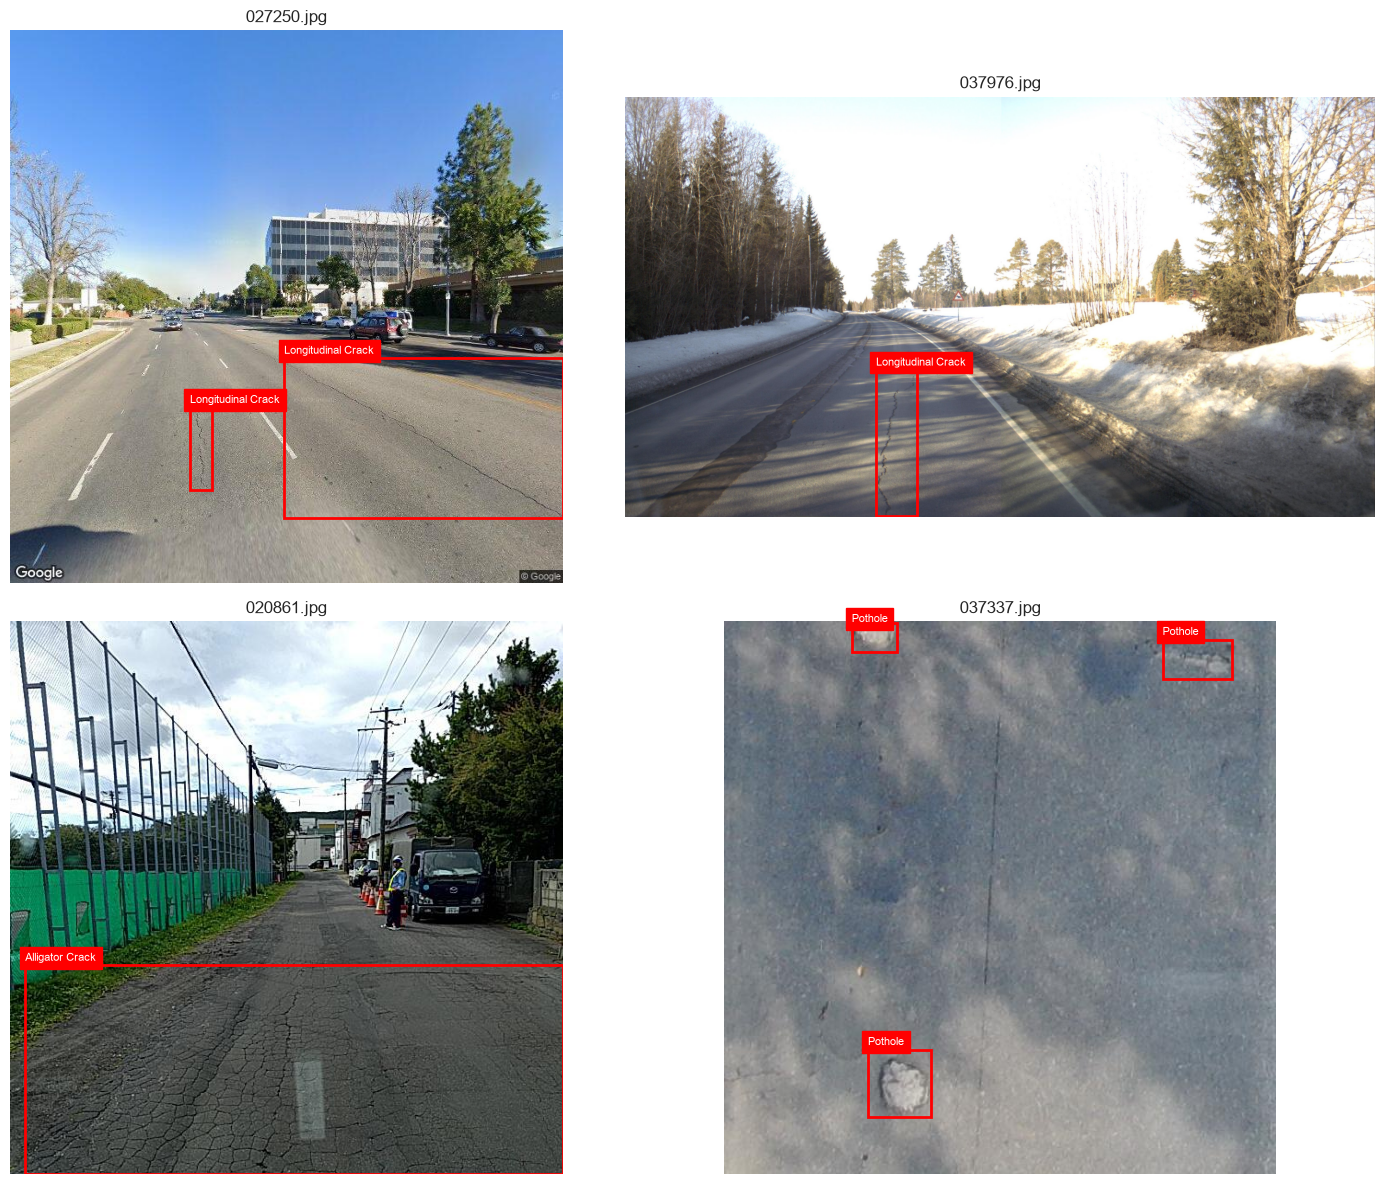

In [7]:

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path
import random

DATASET_ROOT = Path(path) / "randomized_dataset"
IMAGE_DIR = DATASET_ROOT / "train" / "images"
LABEL_DIR = DATASET_ROOT / "train" / "labels"

CLASS_MAP = {
    0: "Longitudinal Crack",
    1: "Transverse Crack",
    2: "Alligator Crack",
    3: "Other Corruption",
    4: "Pothole"
}

# Select 4 images that contain annotations
label_files = [
    f for f in LABEL_DIR.glob("*.txt")
    if f.stat().st_size > 0
]

selected = random.sample(label_files, 4)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

for ax, label_file in zip(axes.flatten(), selected):

    # Find corresponding image
    image_path = None

    for ext in [".jpg", ".jpeg", ".png"]:
        candidate = IMAGE_DIR / (label_file.stem + ext)
        if candidate.exists():
            image_path = candidate
            break

    if image_path is None:
        ax.axis("off")
        continue

    img = Image.open(image_path).convert("RGB")
    width, height = img.size

    ax.imshow(img)

    with open(label_file, "r") as f:
        for line in f:
            parts = line.split()

            if len(parts) != 5:
                continue

            cls_id = int(parts[0])
            x, y, w, h = map(float, parts[1:])

            # Convert normalized YOLO coordinates to pixels
            x1 = (x - w / 2) * width
            y1 = (y - h / 2) * height
            box_w = w * width
            box_h = h * height

            rect = patches.Rectangle(
                (x1, y1),
                box_w,
                box_h,
                linewidth=2,
                edgecolor="red",
                facecolor="none"
            )

            ax.add_patch(rect)

            ax.text(
                x1,
                max(0, y1 - 5),
                CLASS_MAP.get(cls_id, "Unknown"),
                color="white",
                fontsize=8,
                backgroundcolor="red"
            )

    ax.set_title(image_path.name)
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:
from pathlib import Path

DATASET_ROOT = Path(path) / "randomized_dataset"

print("Searching for YAML configuration files...\n")

for file in DATASET_ROOT.rglob("*.yaml"):
    print(file)

for file in DATASET_ROOT.rglob("*.yml"):
    print(file)

Searching for YAML configuration files...



In [9]:

from pathlib import Path
import yaml

DATASET_ROOT = Path(path) / "randomized_dataset"

# Create the YOLO dataset configuration
data_config = {
    "path": str(DATASET_ROOT),
    "train": "train/images",
    "val": "val/images",
    "nc": 5,
    "names": [
        "Longitudinal Crack",
        "Transverse Crack",
        "Alligator Crack",
        "Other Corruption",
        "Pothole"
    ]
}

# Save configuration in your project folder
yaml_path = Path.cwd() / "road_damage_data.yaml"

with open(yaml_path, "w") as f:
    yaml.safe_dump(data_config, f, sort_keys=False)

print("YOLO configuration created successfully!")
print("File location:", yaml_path)

with open(yaml_path, "r") as f:
    print("\nConfiguration contents:\n")
    print(f.read())


YOLO configuration created successfully!
File location: /Users/adarshreddy/Desktop/Road-Damage-Detection/road_damage_data.yaml

Configuration contents:

path: /Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset
train: train/images
val: val/images
nc: 5
names:
- Longitudinal Crack
- Transverse Crack
- Alligator Crack
- Other Corruption
- Pothole



In [10]:
from ultralytics.data.utils import check_det_dataset

# Verify the YOLO dataset configuration
dataset_info = check_det_dataset(str(yaml_path))

print("Dataset configuration verified!")
print("\nTraining path:", dataset_info["train"])
print("Validation path:", dataset_info["val"])
print("Number of classes:", dataset_info["nc"])
print("Class names:", dataset_info["names"])

Dataset configuration verified!

Training path: /Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/images
Validation path: /Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/val/images
Number of classes: 5
Class names: {0: 'Longitudinal Crack', 1: 'Transverse Crack', 2: 'Alligator Crack', 3: 'Other Corruption', 4: 'Pothole'}


In [1]:
# STEP 2: Check the YOLOv8 installation and dataset

import torch
import ultralytics
import os

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)
print("MPS available:", torch.backends.mps.is_available())

# Check dataset location
dataset_path = os.path.expanduser(
    "~/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset"
)

print("\nDataset exists:", os.path.exists(dataset_path))
print("Dataset folders:", os.listdir(dataset_path))

PyTorch version: 2.15.0
Ultralytics version: 8.4.208
MPS available: True

Dataset exists: True
Dataset folders: ['test', 'train', 'val']


In [2]:
from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
model = YOLO("yolov8n.pt")

print("YOLOv8 model loaded successfully!")

# Display model information
model.info()

YOLOv8 model loaded successfully!
YOLOv8n summary: 129 layers, 3,157,200 parameters, 0 gradients, 8.9 GFLOPs


(129, 3157200, 0, 8.8550912)

In [3]:
import random
from pathlib import Path
from IPython.display import Image, display

# Get road images from training dataset
image_folder = Path(dataset_path) / "train" / "images"
image_files = list(image_folder.glob("*.jpg")) + list(image_folder.glob("*.png"))

# Select one random image
sample_image = random.choice(image_files)

print("Testing image:", sample_image.name)

# Run pretrained YOLO prediction
results = model.predict(
    source=str(sample_image),
    conf=0.25,
    device="mps",
    save=True
)

# Display detected image
display(Image(filename=results[0].save_dir / sample_image.name))

Testing image: 032442.jpg

image 1/1 /Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset/train/images/032442.jpg: 352x640 (no detections), 3.3ms
Speed: 422.8ms preprocess, 3.3ms inference, 22.5ms postprocess per image at shape (1, 3, 352, 640)
Results saved to /Users/adarshreddy/Desktop/Road-Damage-Detection/runs/detect/predict


TypeError: unsupported operand type(s) for /: 'str' and 'str'

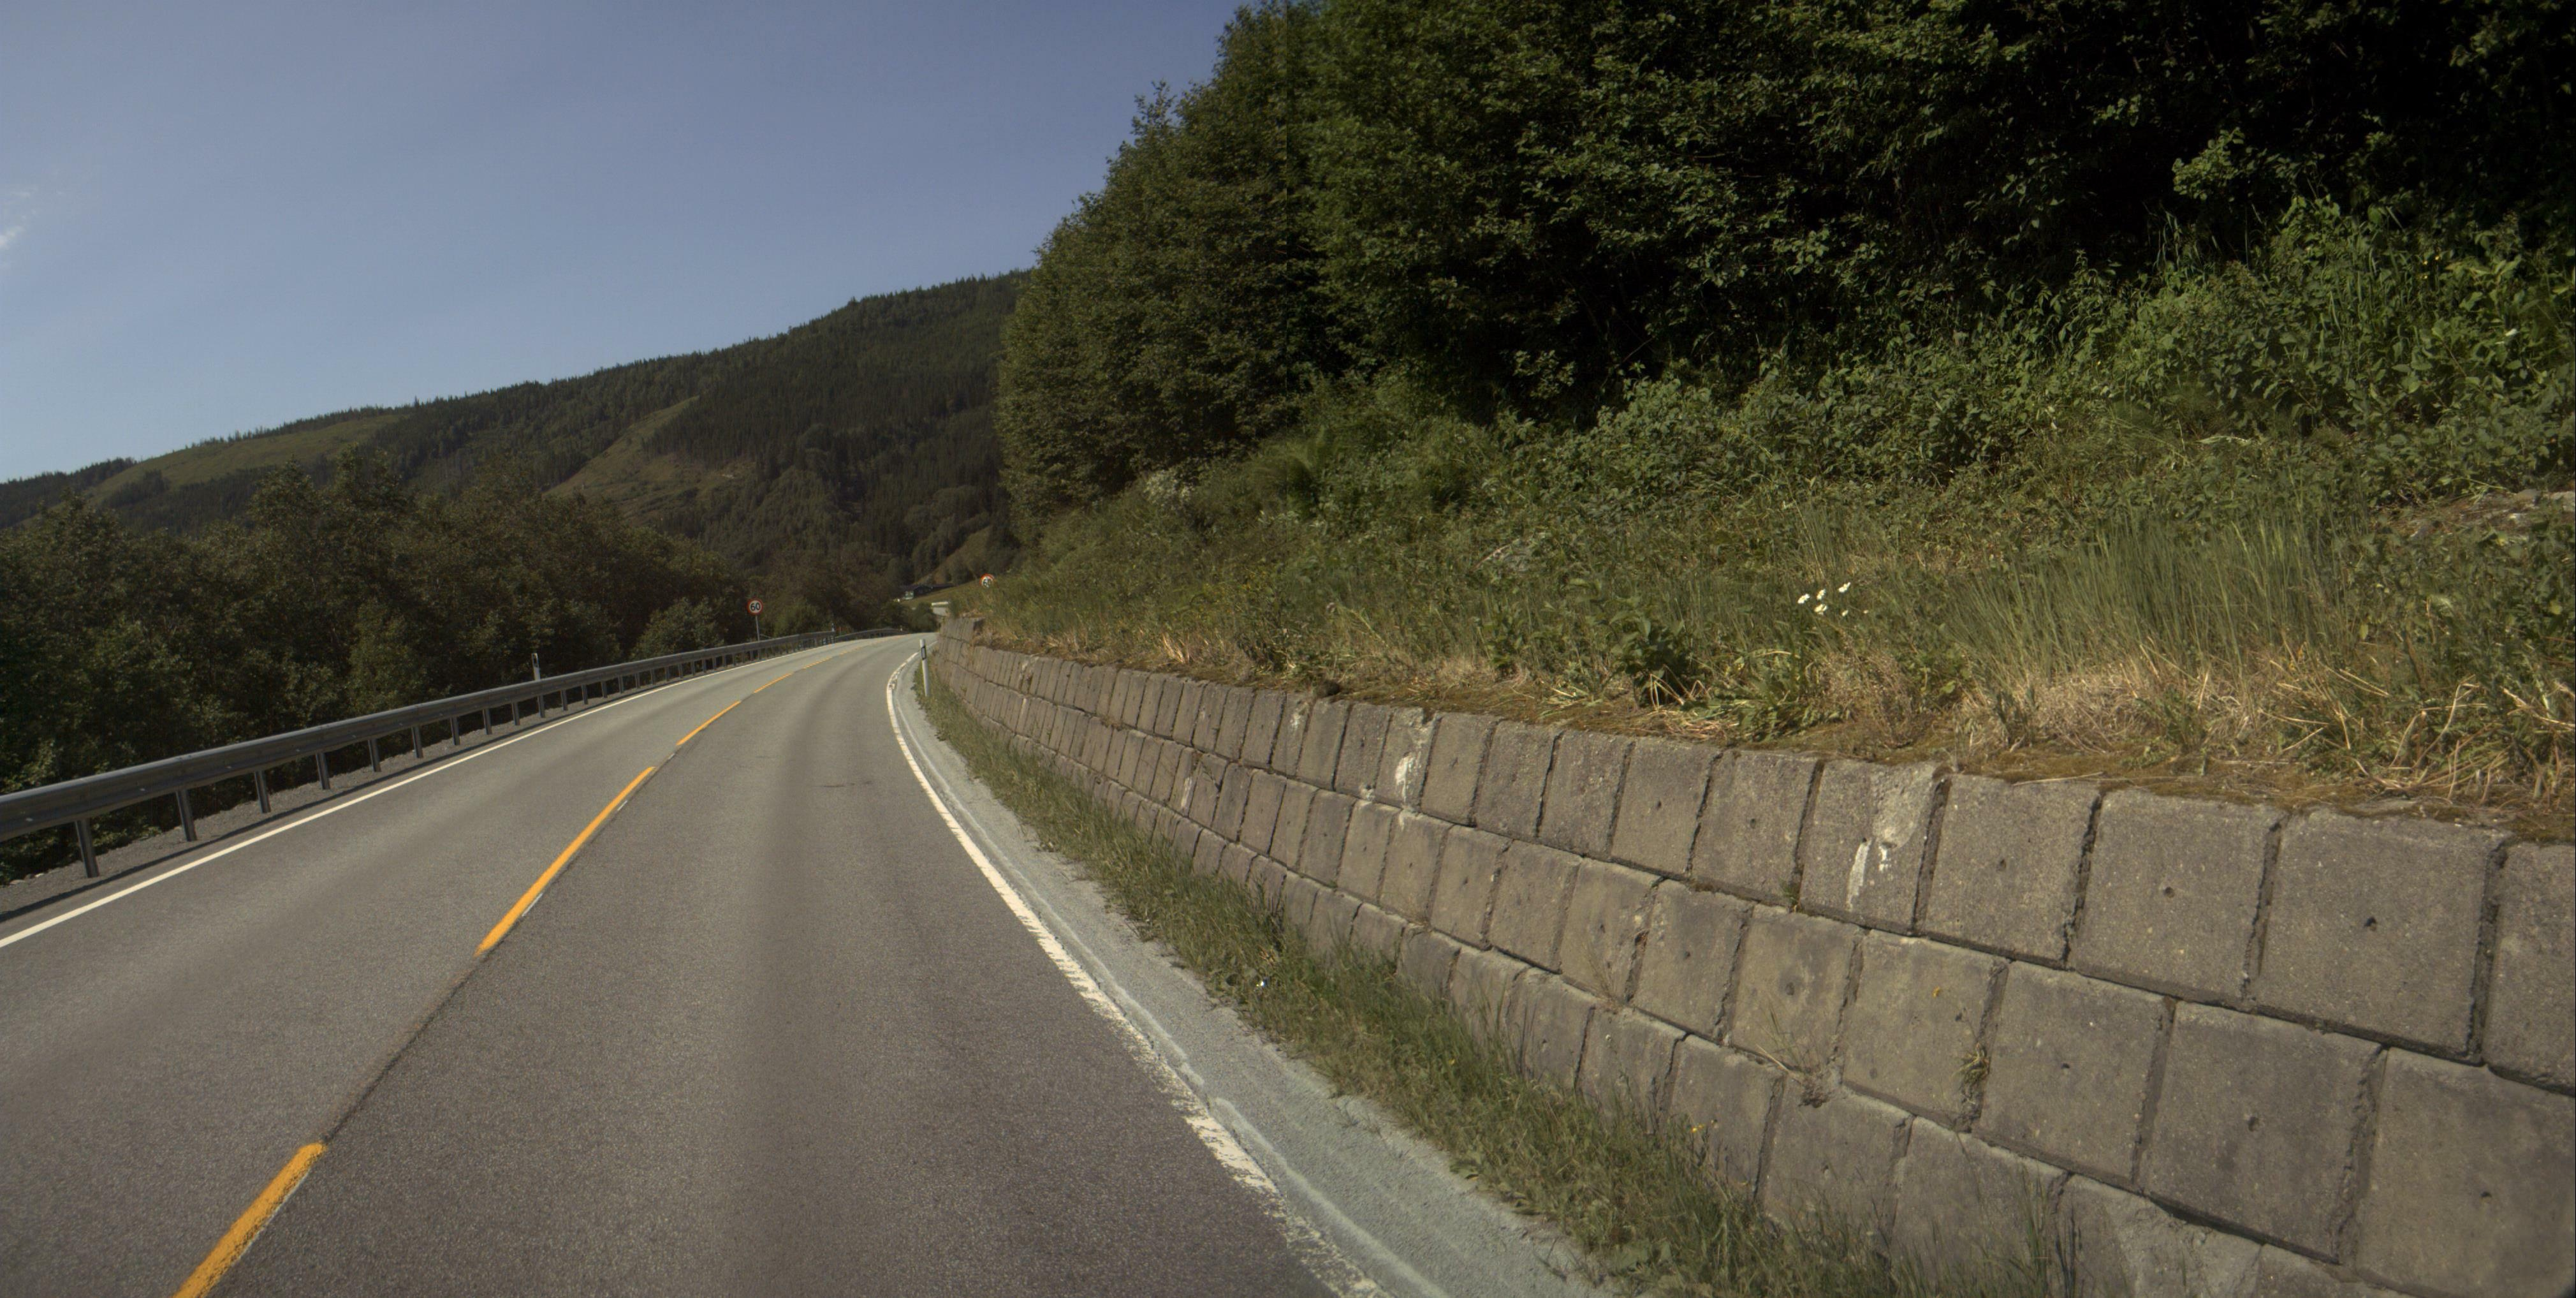

In [4]:
from IPython.display import Image, display
from pathlib import Path

# Get the saved prediction image
saved_image = Path(results[0].save_dir) / sample_image.name

# Display it
display(Image(filename=str(saved_image)))

In [5]:
from pathlib import Path
import yaml

yaml_path = Path.home() / "Desktop" / "Road-Damage-Detection" / "road_damage_data.yaml"

with open(yaml_path, "r") as file:
    data_config = yaml.safe_load(file)

print("Dataset configuration:")
print(data_config)

print("\nNumber of classes:", data_config["nc"])
print("Class names:", data_config["names"])
print("Training images folder exists:",
      (Path(data_config["path"]) / data_config["train"]).exists())
print("Validation images folder exists:",
      (Path(data_config["path"]) / data_config["val"]).exists())

Dataset configuration:
{'path': '/Users/adarshreddy/.cache/kagglehub/datasets/anulayakhare/crackathon-data/versions/1/randomized_dataset', 'train': 'train/images', 'val': 'val/images', 'nc': 5, 'names': ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']}

Number of classes: 5
Class names: ['Longitudinal Crack', 'Transverse Crack', 'Alligator Crack', 'Other Corruption', 'Pothole']
Training images folder exists: True
Validation images folder exists: True


In [6]:
# STEP 7: Prepare YOLOv8 baseline experiment

from ultralytics import YOLO

# Load pretrained YOLOv8 Nano model
baseline_model = YOLO("yolov8n.pt")

# Training configuration
baseline_config = {
    "data": str(yaml_path),
    "epochs": 20,
    "imgsz": 640,
    "batch": 16,
    "workers": 2,
    "project": "road_damage_experiments",
    "name": "baseline_yolov8n",
    "pretrained": True,
    "plots": True,
    "save": True
}

print("Baseline experiment prepared!")
print("\nTraining configuration:")

for key, value in baseline_config.items():
    print(f"{key}: {value}")

Baseline experiment prepared!

Training configuration:
data: /Users/adarshreddy/Desktop/Road-Damage-Detection/road_damage_data.yaml
epochs: 20
imgsz: 640
batch: 16
workers: 2
project: road_damage_experiments
name: baseline_yolov8n
pretrained: True
plots: True
save: True
